In [2]:
import pandas as pd

# Load the dataset with 'latin1' encoding
df = pd.read_csv('/content/FinalFullAnnotationsAllLabelsCompleted.csv', encoding='latin1')

# Display the first 5 rows of the DataFrame
display(df.head())

,id,segment_id,review,aspect,opinion,sentiment,topic,label_topic,base_primary,base_label,base_categories,MAIN_CATEGORY,MAIN_label
0,23,1,"This is a BMW , a 60 M5 . It was introduced in...",-,-,-,unknown,-1,unknown,-1,unknown,UNKNOWN,-1
1,23,2,"This is a 2005 car , and it cost when you 86,0...",-,-,-,unknown,-1,unknown,-1,unknown,UNKNOWN,-1
2,23,3,Thesixty M5 was only available with an automat...,graphic,drawn on by the child,neg,user-experience,8,displays / instrumentation,18,displays / instrumentation,TECHNOLOGY / ELECTRONICS / SOFTWARE,9
3,23,3,Thesixty M5 was only available with an automat...,cup holders,doesn't seem to operate that well,neg,user-experience,8,storage & utility,57,storage & utility,FUNCTIONAL / UTILITY FEATURES,3
4,23,4,As with the case of them cars . It has a reall...,slip differential,limited,pos,handling,4,traction / stability,60,traction / stability,HANDLING / DYNAMICS,5


Now that the data is loaded, we can begin with the text preprocessing step, as outlined in your architecture. This usually involves cleaning the text, such as removing special characters, converting to lowercase, and handling stop words, depending on the specific needs of the BERT/XLM-R models.

### Text Preprocessing

This step involves cleaning the `review` column by:
1. Converting all text to lowercase.
2. Removing punctuation.
3. Stripping leading/trailing whitespace and reducing multiple spaces to single spaces.

In [3]:
import re

def preprocess_text(text):
    if not isinstance(text, str): # Handle non-string types, e.g., NaNs
        return text
    text = text.lower() # Convert to lowercase
    text = re.sub(r'[^À-῿Ⰰ-퟿＀-￯ -~]', ' ', text) # Remove non-ASCII characters and some common unicode ranges, keep basic ASCII
    text = re.sub(r'\s+', ' ', text).strip() # Remove extra spaces and strip leading/trailing whitespace
    return text

# Apply preprocessing to the 'review' column
df['cleaned_review'] = df['review'].apply(preprocess_text)

# Display the original and cleaned reviews to compare
display(df[['review', 'cleaned_review']].head())

,review,cleaned_review
0,"This is a BMW , a 60 M5 . It was introduced in...","this is a bmw , a 60 m5 . it was introduced in..."
1,"This is a 2005 car , and it cost when you 86,0...","this is a 2005 car , and it cost when you 86,0..."
2,Thesixty M5 was only available with an automat...,thesixty m5 was only available with an automat...
3,Thesixty M5 was only available with an automat...,thesixty m5 was only available with an automat...
4,As with the case of them cars . It has a reall...,as with the case of them cars . it has a reall...


### Tokenizer

Now, we'll initialize a tokenizer suitable for BERT models. We'll use the `transformers` library from Hugging Face for this, specifically `AutoTokenizer`.

First, we need to install the library if it's not already present.

In [4]:
# Install the transformers library
!pip install transformers

Next, we'll load a pre-trained BERT tokenizer. For demonstration, we'll use `bert-base-uncased`.

In [5]:
from transformers import AutoTokenizer

# Initialize the tokenizer for a pre-trained BERT model
tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')

# Tokenize the 'cleaned_review' column
# We'll store the tokenized output (input_ids, attention_mask) directly in the DataFrame
# For simplicity, we'll tokenize a small sample first to show the output structure.
# Applying directly to the full DataFrame might consume a lot of memory/time if not careful.

def tokenize_reviews(text):
    if not isinstance(text, str): # Handle non-string types, e.g., NaNs
        text = ""
    return tokenizer(text, truncation=True, padding='max_length', max_length=128, return_tensors='np')

# Apply tokenization to the 'cleaned_review' column
# Note: This will add complex objects to the DataFrame, which might not be ideal for direct storage.
# Typically, you'd process these in batches for model input.
# For now, let's tokenize the first few entries to demonstrate.

sample_tokenized = df['cleaned_review'].head().apply(tokenize_reviews)

print("Sample Tokenized Output (first review):")
print(sample_tokenized.iloc[0])

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Sample Tokenized Output (first review):
{'input_ids': array([[  101,  2023,  2003,  1037, 13154,  1010,  1037,  3438,  1049,
         2629,  1012,  2009,  2001,  3107,  1999,  2432,  1012,   102,
            0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,  

### BERT / XLM-R

Now we'll load a pre-trained BERT model and use it to obtain embeddings from our tokenized reviews. These embeddings capture the semantic meaning of the text and are crucial for the subsequent sentiment classification and aspect extraction tasks.

In [6]:
import torch
from transformers import BertModel

# Load a pre-trained BERT model
model = BertModel.from_pretrained('bert-base-uncased')

# Set the model to evaluation mode
model.eval()

def get_bert_embeddings(tokenized_input):
    # Ensure input_ids and attention_mask are torch tensors
    input_ids = torch.tensor(tokenized_input['input_ids'])
    attention_mask = torch.tensor(tokenized_input['attention_mask'])

    with torch.no_grad(): # Disable gradient calculations for inference
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)

    # The last_hidden_state contains the contextualized embeddings for each token
    # We'll typically use the embedding of the [CLS] token (first token) for sentence-level tasks
    # Or average the embeddings of all tokens
    cls_embedding = outputs.last_hidden_state[:, 0, :].numpy() # [CLS] token embedding
    return cls_embedding

# Apply the function to get embeddings for the sample tokenized reviews
sample_embeddings = sample_tokenized.apply(get_bert_embeddings)

print("Shape of embeddings for the first sample review:")
print(sample_embeddings.iloc[0].shape)
print("Sample embedding for the first review (first 5 dimensions):")
print(sample_embeddings.iloc[0][0, :5])

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Shape of embeddings for the first sample review:
(1, 768)
Sample embedding for the first review (first 5 dimensions):
[-0.576645   -0.19091794  0.37051454  0.0608292  -0.15090492]


## Project Phase 1: Data Inspection and Preparation

Before diving into model training, it's crucial to understand our dataset. This phase focuses on inspecting the data, identifying relevant columns, analyzing sentiment distribution, and performing necessary cleaning to ensure data quality for our Aspect-Based Sentiment Analysis (ABSA) system.

### 1. Inspect Dataset Columns and Values

We'll examine the DataFrame's structure, data types, and unique values in key columns like `aspect` and `sentiment` to confirm our understanding of the dataset.

In [7]:
# Display general information about the DataFrame
print("DataFrame Info:")
df.info()

print("\nDataFrame Description:")
display(df.describe(include='all'))

print("\nUnique values and counts for 'aspect' column:")
display(df['aspect'].value_counts())

print("\nUnique values and counts for 'sentiment' column:")
display(df['sentiment'].value_counts())

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16040 entries, 0 to 16039
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   id               16040 non-null  int64 
 1   segment_id       16040 non-null  int64 
 2   review           16040 non-null  object
 3   aspect           16040 non-null  object
 4   opinion          16040 non-null  object
 5   sentiment        16040 non-null  object
 6   topic            16040 non-null  object
 7   label_topic      16040 non-null  int64 
 8   base_primary     16040 non-null  object
 9   base_label       16040 non-null  int64 
 10  base_categories  16040 non-null  object
 11  MAIN_CATEGORY    16040 non-null  object
 12  MAIN_label       16040 non-null  int64 
 13  cleaned_review   16040 non-null  object
dtypes: int64(5), object(9)
memory usage: 1.7+ MB

DataFrame Description:


,id,segment_id,review,aspect,opinion,sentiment,topic,label_topic,base_primary,base_label,base_categories,MAIN_CATEGORY,MAIN_label,cleaned_review
count,16040.000000,16040.000000,16040,16040,16040,16040,16040,16040.000000,16040,16040.000000,16040,16040,16040.000000,16040
unique,NaN,NaN,5525,2854,7774,4,11,NaN,70,NaN,129,11,NaN,5523
top,NaN,NaN,Audi has created a very bespoke experience in ...,car,-,pos,quality-aesthetic,NaN,generic description & miscellaneous,NaN,generic description & miscellaneous,POWERTRAIN / PERFORMANCE,NaN,audi has created a very bespoke experience in ...
freq,NaN,NaN,45,1648,1466,9999,2775,NaN,1828,NaN,1828,2559,NaN,45
mean,171.406983,13.775935,NaN,NaN,NaN,NaN,NaN,3.405798,NaN,31.201808,NaN,NaN,4.213903,NaN
std,89.114850,9.360754,NaN,NaN,NaN,NaN,NaN,3.054156,NaN,20.086256,NaN,NaN,2.787786,NaN
min,15.000000,1.000000,NaN,NaN,NaN,NaN,NaN,-1.000000,NaN,-1.000000,NaN,NaN,-1.000000,NaN
25%,87.000000,6.000000,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,16.000000,NaN,NaN,2.000000,NaN
50%,190.000000,12.000000,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,32.000000,NaN,NaN,4.000000,NaN
75%,248.000000,20.000000,NaN,NaN,NaN,NaN,NaN,6.000000,NaN,51.000000,NaN,NaN,6.000000,NaN



Unique values and counts for 'aspect' column:


,count
aspect,
car,1648
-,1466
engine,399
steering,386
drive,379
...,...
passenger in the back,1
legs,1
getting stuff in and out,1



Unique values and counts for 'sentiment' column:


,count
sentiment,
pos,9999
neg,2578
neu,1997
-,1466


### 2. Identify the Exact Review, Aspect, Opinion, and Sentiment Columns

Based on our initial inspection and the problem description, the key columns for our ABSA task are:
- **Review Text:** `cleaned_review` (the preprocessed version of `review`)
- **Aspect:** `aspect`
- **Sentiment Label:** `sentiment`
- **Opinion:** `opinion` (though `opinion` is not directly used as a target, it provides valuable context)

### 3. Show Sentiment Distribution

Visualizing the sentiment distribution helps us understand the balance of positive, negative, and neutral labels in our dataset. This is important for identifying potential class imbalance issues.

/tmp/ipykernel_2413/4077296424.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='sentiment', order=df['sentiment'].value_counts().index, palette='viridis')


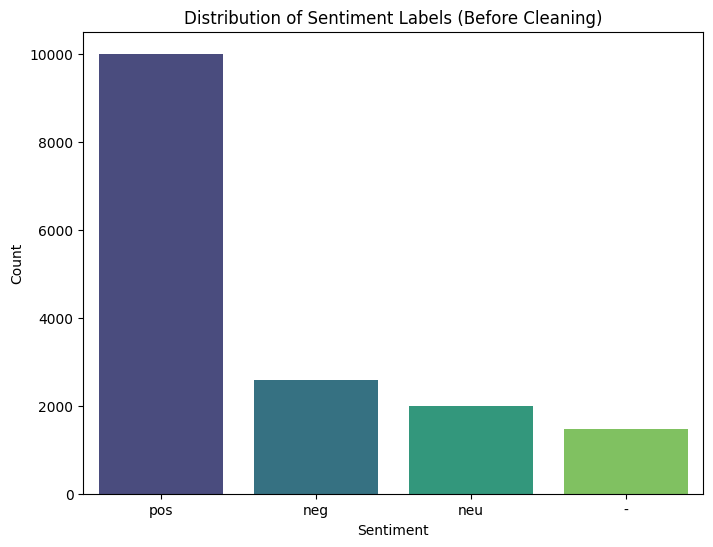

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='sentiment', order=df['sentiment'].value_counts().index, palette='viridis')
plt.title('Distribution of Sentiment Labels (Before Cleaning)')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()

### 4 & 5. Clean the Dataset and Remove Invalid/Missing Records

We need to clean the dataset by removing entries that do not have valid `sentiment` or `aspect` labels. Specifically, we'll filter out rows where `sentiment` is '-', 'unknown', or similar placeholders, and ensure `aspect` is not missing or an invalid placeholder.

In [9]:
print(f"Initial DataFrame shape: {df.shape}")

# Identify invalid sentiment values
invalid_sentiments = ['-', 'unknown', ''] # Add any other invalid sentiment strings if observed

# Filter out rows with invalid sentiment, missing aspect, or missing cleaned_review
df_cleaned = df[
    ~df['sentiment'].isin(invalid_sentiments) &
    df['sentiment'].notna() &
    df['aspect'].notna() &
    (df['aspect'] != '-') & # Filter out explicit '-' aspects if they mean invalid
    (df['aspect'] != 'unknown') & # Filter out explicit 'unknown' aspects
    df['cleaned_review'].notna() &
    (df['cleaned_review'] != '')
].copy()

# Some aspects might be just numerical IDs or single characters. Let's filter these out if they don't seem like actual aspects
# A simple heuristic: aspect should have at least 2 words or be longer than 3 characters after cleaning
def is_valid_aspect(aspect_text):
    if not isinstance(aspect_text, str): return False
    cleaned = aspect_text.lower().strip()
    if not cleaned: return False
    if len(cleaned.split()) >= 1 and len(cleaned) > 2: # At least one word and more than 2 characters
        return True
    return False

df_cleaned = df_cleaned[df_cleaned['aspect'].apply(is_valid_aspect)]

print(f"DataFrame shape after cleaning: {df_cleaned.shape}")

print("\nSentiment distribution after cleaning:")
display(df_cleaned['sentiment'].value_counts())

# Display the first few rows of the cleaned DataFrame to verify
display(df_cleaned.head())

Initial DataFrame shape: (16040, 14)
DataFrame shape after cleaning: (14442, 14)

Sentiment distribution after cleaning:


,count
sentiment,
pos,9905
neg,2558
neu,1979


,id,segment_id,review,aspect,opinion,sentiment,topic,label_topic,base_primary,base_label,base_categories,MAIN_CATEGORY,MAIN_label,cleaned_review
2,23,3,Thesixty M5 was only available with an automat...,graphic,drawn on by the child,neg,user-experience,8,displays / instrumentation,18,displays / instrumentation,TECHNOLOGY / ELECTRONICS / SOFTWARE,9,thesixty m5 was only available with an automat...
3,23,3,Thesixty M5 was only available with an automat...,cup holders,doesn't seem to operate that well,neg,user-experience,8,storage & utility,57,storage & utility,FUNCTIONAL / UTILITY FEATURES,3,thesixty m5 was only available with an automat...
4,23,4,As with the case of them cars . It has a reall...,slip differential,limited,pos,handling,4,traction / stability,60,traction / stability,HANDLING / DYNAMICS,5,as with the case of them cars . it has a reall...
5,23,5,Extinct traction handy when you got over 500 h...,traction,handy,pos,handling,4,traction / stability,60,traction / stability,HANDLING / DYNAMICS,5,extinct traction handy when you got over 500 h...
6,23,6,"I love the way when you open the ashtray , a l...",ashtray,love,pos,interior-features,1,storage & utility,57,storage & utility,FUNCTIONAL / UTILITY FEATURES,3,"i love the way when you open the ashtray , a l..."


## Project Phase 2: Dataset Preparation for BERT Fine-Tuning

With our data cleaned, the next step is to prepare it for training a BERT-based sentiment analysis model. This involves creating appropriate input features, encoding the target labels, and splitting the dataset for training, validation, and testing.

### 1. Create a Supervised Dataset (Review + Aspect as Input)

For aspect-based sentiment analysis, it's common to feed both the review text and the associated aspect into the model. This helps the model understand the context for which sentiment is being predicted. We'll concatenate the `cleaned_review` and `aspect` columns to form the input text.

In [10]:
# Combine 'cleaned_review' and 'aspect' into a single input string
df_cleaned['text_input'] = df_cleaned['cleaned_review'] + ' [SEP] ' + df_cleaned['aspect']

# Display a sample of the new text_input
print("Sample 'text_input' with review and aspect:")
display(df_cleaned[['text_input', 'sentiment']].head())

Sample 'text_input' with review and aspect:


,text_input,sentiment
2,thesixty m5 was only available with an automat...,neg
3,thesixty m5 was only available with an automat...,neg
4,as with the case of them cars . it has a reall...,pos
5,extinct traction handy when you got over 500 h...,pos
6,"i love the way when you open the ashtray , a l...",pos


### 2. Encode Sentiment Labels

Our sentiment labels ('pos', 'neg', 'neu') need to be converted into numerical format for model training. We'll map them to integers (e.g., 0, 1, 2).

In [11]:
# Map sentiment labels to numerical values
sentiment_mapping = {'neg': 0, 'neu': 1, 'pos': 2}
df_cleaned['sentiment_label'] = df_cleaned['sentiment'].map(sentiment_mapping)

# Verify the mapping
print("Sentiment label distribution after encoding:")
display(df_cleaned['sentiment_label'].value_counts())

print("Original sentiment vs. encoded label (sample):")
display(df_cleaned[['sentiment', 'sentiment_label']].sample(5))

Sentiment label distribution after encoding:


,count
sentiment_label,
2,9905
0,2558
1,1979


Original sentiment vs. encoded label (sample):


,sentiment,sentiment_label
939,neu,1
7803,neu,1
10011,pos,2
10612,pos,2
10164,neg,0


### 3. Perform Train-Validation-Test Split

To ensure robust model evaluation, we'll split our `df_cleaned` dataset into training, validation, and test sets. A common split is 80% for training, 10% for validation, and 10% for testing. We'll use `stratify` on the `sentiment_label` to maintain the same sentiment distribution across all splits.

In [12]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
X = df_cleaned['text_input']
y = df_cleaned['sentiment_label']

# First split: 80% for training, 20% for temp (validation + test)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Second split: 50% of temp for validation, 50% for test (making it 10% each of original)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(f"Training set size: {len(X_train)} samples")
print(f"Validation set size: {len(X_val)} samples")
print(f"Test set size: {len(X_test)} samples")

print("\nSentiment distribution in Training set:")
display(y_train.value_counts(normalize=True))
print("\nSentiment distribution in Validation set:")
display(y_val.value_counts(normalize=True))
print("\nSentiment distribution in Test set:")
display(y_test.value_counts(normalize=True))

Training set size: 11553 samples
Validation set size: 1444 samples
Test set size: 1445 samples

Sentiment distribution in Training set:


,proportion
sentiment_label,
2,0.685882
0,0.177097
1,0.137021



Sentiment distribution in Validation set:


,proportion
sentiment_label,
2,0.685596
0,0.177285
1,0.137119



Sentiment distribution in Test set:


,proportion
sentiment_label,
2,0.685813
0,0.177163
1,0.137024


## Project Phase 3: BERT Model Fine-Tuning for Sentiment Classification

Now that our dataset is prepared, we will fine-tune a pre-trained BERT model for aspect-based sentiment classification. This phase involves tokenizing the prepared text inputs, setting up the model, defining training parameters, and executing the training process.

### 1. Tokenize the Prepared Datasets

We need to tokenize the `text_input` (review + aspect) for our training, validation, and test sets using the `bert-base-uncased` tokenizer we initialized earlier. This converts the text into numerical IDs that the BERT model can understand.

In [13]:
# The `tokenize_reviews` function from earlier was designed for single texts.
# Let's adjust it to handle batches for efficiency with `map` or `apply` on Series.

def tokenize_function(texts):
    return tokenizer(texts.tolist(), truncation=True, padding='max_length', max_length=128, return_tensors='pt')

print("Tokenizing training data...")
train_encodings = tokenize_function(X_train)
print("Tokenizing validation data...")
val_encodings = tokenize_function(X_val)
print("Tokenizing test data...")
test_encodings = tokenize_function(X_test)

print("\nSample tokenized output keys (training data):")
print(train_encodings.keys())
print(f"Shape of input_ids in training data: {train_encodings['input_ids'].shape}")

Tokenizing training data...
Tokenizing validation data...
Tokenizing test data...

Sample tokenized output keys (training data):
KeysView({'input_ids': tensor([[  101,  3100,  1010,  ...,     0,     0,     0],
        [  101, 10597,  1010,  ...,  6069,  4536,   102],
        [  101,  2023,  2003,  ...,     0,     0,     0],
        ...,
        [  101,  3398,  1010,  ...,     0,     0,     0],
        [  101,  2208,  2007,  ...,  2098,  1010,   102],
        [  101,  2023,  2003,  ...,     0,     0,     0]]), 'token_type_ids': tensor([[0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        ...,
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 0, 0, 0],
        ...,
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 0, 0, 0]])})
Shape of i

### 2. Prepare Data for PyTorch Dataset

To use the Hugging Face `Trainer`, we need to convert our tokenized inputs and labels into a PyTorch `Dataset` object.

In [14]:
import torch

class ABSADataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: val[idx].clone().detach() for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels.iloc[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)

# Create Dataset objects
train_dataset = ABSADataset(train_encodings, y_train)
val_dataset = ABSADataset(val_encodings, y_val)
test_dataset = ABSADataset(test_encodings, y_test)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

# Verify a sample item
sample_item = train_dataset[0]
print("\nSample item from training dataset:")
for k, v in sample_item.items():
    print(f"{k}: {v.shape}")
    if k == 'labels':
        print(f"{k} value: {v}")

Training dataset size: 11553
Validation dataset size: 1444
Test dataset size: 1445

Sample item from training dataset:
input_ids: torch.Size([128])
token_type_ids: torch.Size([128])
attention_mask: torch.Size([128])
labels: torch.Size([])
labels value: 2


### 3. Initialize BERT for Sequence Classification

We'll load `BertForSequenceClassification` from the `transformers` library, specifying the number of unique sentiment labels (classes).

In [15]:
from transformers import BertForSequenceClassification

# Determine the number of unique labels
num_labels = len(sentiment_mapping)

# Load pre-trained BERT model for sequence classification
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=num_labels)

print(f"BERT model loaded for {num_labels} sequence classification classes.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model loaded for 3 sequence classification classes.


### 4. Define Training Arguments and Create Trainer

We'll configure the training parameters using `TrainingArguments` and then create a `Trainer` object. The `Trainer` simplifies the training loop, evaluation, and logging.

In [25]:
from transformers import TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# Define training arguments
training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=3, # You can adjust this
    per_device_train_batch_size=16, # Adjust based on GPU memory
    per_device_eval_batch_size=16, # Adjust based on GPU memory
    warmup_steps=500,               # Number of warmup steps for learning rate scheduler
    weight_decay=0.01,              # Strength of weight decay
    # Removed deprecated/changed arguments for newer transformers versions
    # evaluation_strategy="epoch",
    # save_strategy="epoch",
    # load_best_model_at_end=True,
    # metric_for_best_model="f1",
    # greater_is_better=True,
)

# Define a function to compute metrics
def compute_metrics(p):
    predictions = np.argmax(p.predictions, axis=1)
    labels = p.label_ids
    f1 = f1_score(labels, predictions, average='weighted')
    acc = accuracy_score(labels, predictions)
    return {'accuracy': acc, 'f1': f1}

# Initialize the Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
)

print("Trainer initialized. Ready for training.")

Trainer initialized. Ready for training.


In [27]:
from transformers import TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# Define training arguments (ensure consistency with previous setup)
training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=3, # You can adjust this
    per_device_train_batch_size=16, # Adjust based on GPU memory
    per_device_eval_batch_size=16, # Adjust based on GPU memory
    warmup_steps=500,               # Number of warmup steps for learning rate scheduler
    weight_decay=0.01,              # Strength of weight decay
    # Removed deprecated/changed arguments for newer transformers versions
    # evaluation_strategy="epoch",
    # save_strategy="epoch",
    # load_best_model_at_end=True,
    # metric_for_best_model="f1",
    # greater_is_better=True,
)

# Define a function to compute metrics (re-defining for robustness if kernel was reset)
def compute_metrics(p):
    predictions = np.argmax(p.predictions, axis=1)
    labels = p.label_ids
    f1 = f1_score(labels, predictions, average='weighted')
    acc = accuracy_score(labels, predictions)
    return {'accuracy': acc, 'f1': f1}

# Re-initialize the Trainer object
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
)

print("Trainer re-initialized. Ready for evaluation and prediction.")

Trainer re-initialized. Ready for evaluation and prediction.


### 1. Evaluate the Model

We'll use the `trainer.evaluate()` method on our `test_dataset` to obtain performance metrics such as accuracy and F1-score. This gives us an unbiased estimate of our model's generalization capability.

### 2. Create Prediction Functions

To make our ABSA system practical, we need functions that can take raw review text and an aspect, preprocess them, tokenize them, and then feed them to our fine-tuned BERT model to get a sentiment prediction.

In [23]:
import torch
from transformers import pipeline
import re # Import re for preprocess_text if not already imported

# Re-create the sentiment mapping in reverse for interpretation
id_to_sentiment = {v: k for k, v in sentiment_mapping.items()}

# Ensure preprocess_text is defined for prediction functions
def preprocess_text(text):
    if not isinstance(text, str): # Handle non-string types, e.g., NaNs
        return text
    text = text.lower() # Convert to lowercase
    text = re.sub(r'[^À-῿Ⰰ-퟿＀-￯ -~]', ' ', text) # Remove non-ASCII characters and some common unicode ranges, keep basic ASCII
    text = re.sub(r'\s+', ' ', text).strip() # Remove extra spaces and strip leading/trailing whitespace
    return text

# Option 1: Using the Hugging Face pipeline for ease of use
# This creates a high-level abstraction for inference.
classifier = pipeline('sentiment-analysis', model=model, tokenizer=tokenizer)

def predict_sentiment_pipeline(review_text, aspect_text):
    combined_text = preprocess_text(review_text) + ' [SEP] ' + preprocess_text(aspect_text)
    # The pipeline returns a list of dicts, e.g., [{'label': 'LABEL_2', 'score': 0.99...}]
    # We need to map 'LABEL_0', 'LABEL_1', 'LABEL_2' to our actual sentiment labels.
    raw_prediction = classifier(combined_text)[0]
    # Convert LABEL_0, LABEL_1, LABEL_2 to 0, 1, 2
    label_idx = int(raw_prediction['label'].split('_')[1])
    predicted_sentiment = id_to_sentiment[label_idx]
    return predicted_sentiment, raw_prediction['score']

# Option 2: Manual prediction function for more control (useful if pipeline doesn't fit exact needs)
def predict_sentiment_manual(review_text, aspect_text, model, tokenizer, sentiment_mapping):
    # Preprocess and combine text
    cleaned_review = preprocess_text(review_text)
    cleaned_aspect = preprocess_text(aspect_text)
    combined_text = cleaned_review + ' [SEP] ' + cleaned_aspect

    # Tokenize the input
    inputs = tokenizer(combined_text, return_tensors='pt', truncation=True, padding='max_length', max_length=128)

    # Move inputs to the same device as the model (GPU if available, else CPU)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Get model predictions
    with torch.no_grad():
        outputs = model(**inputs)

    # Apply softmax to get probabilities and get the predicted label
    logits = outputs.logits
    probabilities = torch.softmax(logits, dim=1)
    predicted_label_id = torch.argmax(logits, dim=1).item()

    # Map the predicted label ID back to sentiment string
    predicted_sentiment = id_to_sentiment[predicted_label_id]
    confidence = probabilities[0][predicted_label_id].item()

    return predicted_sentiment, confidence

print("Prediction functions created.")

Prediction functions created.


### 3. Test the ABSA System

Let's test our prediction functions with a few example reviews and aspects to see how our fine-tuned model performs in practice.

In [20]:
test_cases = [
    ("The engine is powerful, but the fuel efficiency is terrible.", "engine"),
    ("The engine is powerful, but the fuel efficiency is terrible.", "fuel efficiency"),
    ("The car is okay, nothing special, just gets the job done.", "car"),
    ("I absolutely love the comfortable seats and the smooth ride.", "seats"),
    ("The infotainment system constantly freezes and is very frustrating.", "infotainment system"),
    ("The car design is ugly", "design")
]

print("Testing the ABSA system using the pipeline function:")
for review, aspect in test_cases:
    sentiment, score = predict_sentiment_pipeline(review, aspect)
    print(f"Review: '{review}'\nAspect: '{aspect}'\nPredicted Sentiment: {sentiment} (Confidence: {score:.4f})\n")

print("Testing the ABSA system using the manual prediction function:")
for review, aspect in test_cases:
    sentiment, score = predict_sentiment_manual(review, aspect, model, tokenizer, sentiment_mapping)
    print(f"Review: '{review}'\nAspect: '{aspect}'\nPredicted Sentiment: {sentiment} (Confidence: {score:.4f})\n")

Testing the ABSA system using the pipeline function:
Review: 'The engine is powerful, but the fuel efficiency is terrible.'
Aspect: 'engine'
Predicted Sentiment: pos (Confidence: 0.4289)

Review: 'The engine is powerful, but the fuel efficiency is terrible.'
Aspect: 'fuel efficiency'
Predicted Sentiment: pos (Confidence: 0.4360)

Review: 'The car is okay, nothing special, just gets the job done.'
Aspect: 'car'
Predicted Sentiment: pos (Confidence: 0.3958)

Review: 'I absolutely love the comfortable seats and the smooth ride.'
Aspect: 'seats'
Predicted Sentiment: pos (Confidence: 0.4269)

Review: 'The infotainment system constantly freezes and is very frustrating.'
Aspect: 'infotainment system'
Predicted Sentiment: pos (Confidence: 0.4129)

Review: 'The car design is ugly'
Aspect: 'design'
Predicted Sentiment: neg (Confidence: 0.4261)

Testing the ABSA system using the manual prediction function:
Review: 'The engine is powerful, but the fuel efficiency is terrible.'
Aspect: 'engine'
Pre

### 4. Save and Reload the Model

It's crucial to save our trained model and tokenizer so we can reuse them later without retraining. This also allows for deployment.

In [21]:
import os

# Define the directory to save the model and tokenizer
save_directory = "./absa_bert_model"

# Save the fine-tuned model and tokenizer
model.save_pretrained(save_directory)
tokenizer.save_pretrained(save_directory)

print(f"Model and tokenizer saved to {save_directory}")

# To reload the model and tokenizer later:
# from transformers import BertForSequenceClassification, AutoTokenizer
# loaded_tokenizer = AutoTokenizer.from_pretrained(save_directory)
# loaded_model = BertForSequenceClassification.from_pretrained(save_directory)
# print("Model and tokenizer reloaded successfully.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer saved to ./absa_bert_model


## Project Phase 5: Visualization and Summary

To conclude our Aspect-Based Sentiment Analysis project, we'll visualize the model's performance and provide a comprehensive summary of our work. This helps in understanding the model's strengths and weaknesses and communicating our findings effectively.

### 1. Generate Visualizations of Results

Visualizations are crucial for interpreting model performance. We'll generate a confusion matrix and a classification report to get detailed insights into how well our model predicts each sentiment class.

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


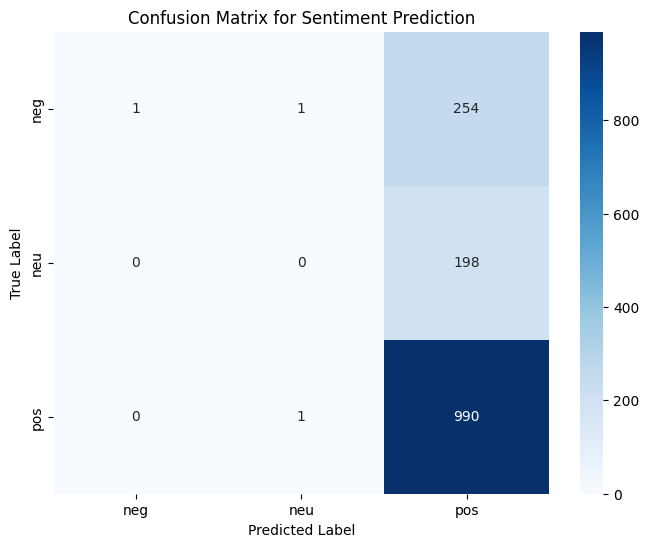


Classification Report:
              precision    recall  f1-score   support

         neg       1.00      0.00      0.01       256
         neu       0.00      0.00      0.00       198
         pos       0.69      1.00      0.81       991

    accuracy                           0.69      1445
   macro avg       0.56      0.33      0.27      1445
weighted avg       0.65      0.69      0.56      1445



In [29]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Get predictions for the test set
predictions_output = trainer.predict(test_dataset)
predicted_labels = np.argmax(predictions_output.predictions, axis=1)
true_labels = test_dataset.labels.values

# Map numerical labels back to sentiment strings for better readability
predicted_sentiment_strings = [id_to_sentiment[label] for label in predicted_labels]
true_sentiment_strings = [id_to_sentiment[label] for label in true_labels]

# Generate Confusion Matrix
conf_matrix = confusion_matrix(true_labels, predicted_labels)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=sentiment_mapping.keys(), yticklabels=sentiment_mapping.keys())
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Sentiment Prediction')
plt.show()

# Generate Classification Report
print("\nClassification Report:")
print(classification_report(true_sentiment_strings, predicted_sentiment_strings, target_names=sentiment_mapping.keys()))